# [실습] 회귀 — 숫자를 예측하고 오차로 말하기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 2 실습. 이 집은 얼마에 팔릴까?

**필수 머신러닝 · Chapter 2**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 베이스라인 고르기 |
| Part 3 | 현행 방법 만들기: 사람의 시세 규칙 |
| Part 4 | 모델 만들기와 실험 기록 |
| Part 5 | 오차 들여다보기와 보고 |

## 분석 의뢰서

> **의뢰 부서**: 부동산 플랫폼 기획팀
> **목적**: 매물을 등록할 때 "이 집은 대략 얼마" 하는 적정 시세를 자동으로 제시하고 싶다.
> **제약**: 시세가 실제 거래가와 너무 다르면 판매자와 구매자 모두 플랫폼을 믿지 않게 된다.
> **질문**: 집의 정보로 거래가를 얼마나 정확히 예측할 수 있을까?

## 이 실습의 질문

> **기획팀에 "이 모델의 시세는 평균적으로 ±얼마"라고 말한다면, 어떤 지표로 얼마라고 말할 것인가? 그리고 그 숫자를 믿어도 되는 집과 믿으면 안 되는 집은 어떻게 다른가?**

Chapter 1과 같은 순서로 진행합니다. 여러분이 먼저 중개사처럼 **사람의 시세 규칙**을 만들고, 그 시세 규칙과 모델을 **같은 평가용 데이터**에서 비교합니다. 마지막에는 기획팀에 보낼 보고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

## 준비

Kaggle의 House Prices 대회 데이터인 `train.csv`(Ames Housing, 1,460채)를 이 노트북과 같은 폴더에 두세요.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

강의에서는 피처 다섯 개만 썼습니다. 여기서는 데이터에 실제로 어떤 문제가 들어 있는지 직접 확인하고, 그 문제를 어떻게 다룰지 스스로 정합니다.

## 1-1. 데이터 불러오기

**[직접 작성]** `train.csv`를 불러와 `df`에 저장하고, 행과 열의 수와 처음 5행을 확인하세요.

<details><summary>힌트</summary>

`pd.read_csv("파일 이름")`, `df.shape`, `df.head()`를 쓰세요. 열이 많아서 `df.head()`는 일부만 보입니다.
</details>

In [2]:
# 여기에 코드를 작성하세요
import pandas as pd

df = pd.read_csv("/content/sample_data/train.csv")

print(df.shape)
df.head()

(1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape LandContour Utilities LotConfig LandSlope Neighborhood Condition1 Condition2 BldgType HouseStyle  OverallQual  OverallCond  YearBuilt  YearRemodAdd RoofStyle RoofMatl Exterior1st Exterior2nd MasVnrType  MasVnrArea ExterQual ExterCond Foundation BsmtQual BsmtCond BsmtExposure BsmtFinType1  BsmtFinSF1 BsmtFinType2  BsmtFinSF2  BsmtUnfSF  TotalBsmtSF Heating HeatingQC CentralAir Electrical  1stFlrSF  2ndFlrSF  LowQualFinSF  GrLivArea  BsmtFullBath  BsmtHalfBath  FullBath  HalfBath  BedroomAbvGr  KitchenAbvGr KitchenQual  TotRmsAbvGrd Functional  Fireplaces FireplaceQu GarageType  GarageYrBlt GarageFinish  GarageCars  GarageArea GarageQual GarageCond PavedDrive  WoodDeckSF  OpenPorchSF  EnclosedPorch  3SsnPorch  ScreenPorch  PoolArea PoolQC Fence MiscFeature  MiscVal  MoSold  YrSold SaleType SaleCondition  SalePrice
0   1          60       RL         65.0     8450   Pave   NaN      Reg         Lvl    AllPub  

## 1-2. 거래가 살펴보기

**[직접 작성]** 거래가(`SalePrice`)의 평균, 중앙값, 최솟값, 최댓값을 확인하세요.

<details><summary>힌트</summary>

`df["SalePrice"].describe()`가 한 번에 보여 줍니다. 중앙값은 `50%` 줄입니다.
</details>

In [3]:
# 여기에 코드를 작성하세요

df["SalePrice"].describe().round(3)

count      1460.000
mean     180921.196
std       79442.503
min       34900.000
25%      129975.000
50%      163000.000
75%      214000.000
max      755000.000
Name: SalePrice, dtype: float64


**[제공]** 거래가의 분포를 그려 봅니다.

<lms-runtime>:1399: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 45804 (\N{HANGUL SYLLABLE DAL}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 47084 (\N{HANGUL SYLLABLE REO}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 51665 (\N{HANGUL SYLLABLE JIB}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 51473 (\N{HANG

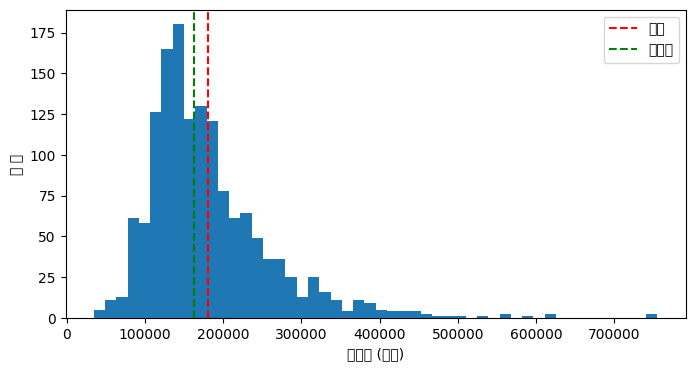

In [4]:
# [제공] 거래가 분포
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["SalePrice"], bins=50)
ax.axvline(df["SalePrice"].mean(), color="red", linestyle="--", label="평균")
ax.axvline(df["SalePrice"].median(), color="green", linestyle="--", label="중앙값")
ax.set_xlabel("거래가 (달러)")
ax.set_ylabel("집 수")
ax.legend()
plt.show()

평균이 중앙값 보다 크다.

대부분의 집은 13만~21만 사이에 몰려 있지만, 상위 소수의 고가 주택(최대 755,000)이 오른쪽으로 길게 뻗어 있습니다. IQR 기준 상한선(214,000 + 1.5 × 84,025 ≈ 340,000)을 훌쩍 넘는 집들이 존재합니다. 평균은 이런 극단값에 끌려 올라가지만 중앙값은 순서만 보기 때문에 영향을 거의 받지 않는다

> **[판단]** 평균과 중앙값 중 어느 쪽이 더 큰가요? 그 이유는 무엇이고, 이 특징이 "모델이 크게 틀리는 집"에 어떤 영향을 줄 것 같나요?
>
> 나의 답:

## 1-3. 빈 값 찾기

**[직접 작성]** 빈 값이 있는 열을 빈 값이 많은 순서로 10개 확인하세요.

<details><summary>힌트</summary>

`df.isna().sum()`은 열마다 빈 값의 수를 셉니다. `.sort_values(ascending=False)`로 정렬하고 `.head(10)`으로 위쪽만 보세요.
</details>

In [5]:
# 여기에 코드를 작성하세요

missing = df.isna().sum().sort_values(ascending=False)
missing.head(10)



PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
dtype: int64


빈 값은 "모름"이 아니라 "수영장 없다"이므로, 삭제하거나 최빈값으로 채우지 않고 "None" 범주로 채운다.

> **[판단]** 수영장 품질(`PoolQC`)이 1,453채나 비어 있습니다. 정말로 정보가 없는 걸까요, 아니면 다른 뜻일까요? 데이터 설명서에서는 이런 열의 빈 값(NA)을 "해당 시설 없음"으로 정의합니다. 이 점을 알면 빈 값을 어떻게 다루겠습니까?
>
> 나의 답:

## 1-4. 이 실습에서 쓰는 피처 정하기

79개를 전부 쓰면 첫 실습으로는 너무 많아서, 이 실습에서 쓸 피처 몇 개를 미리 골라 두었습니다. **[제공]** 셀을 실행해 목록을 확인하세요.

In [6]:
# [제공] 이 실습에서 쓰는 피처 목록
num_features = ["GrLivArea", "OverallQual", "YearBuilt", "YearRemodAdd", "TotalBsmtSF", "GarageCars",
                "GarageArea", "LotArea", "FullBath", "TotRmsAbvGrd", "Fireplaces", "1stFlrSF"]
cat_features = ["Neighborhood", "ExterQual", "KitchenQual", "BsmtQual", "CentralAir", "MSSubClass"]

print("숫자형:", num_features)
print("범주형:", cat_features)
print()
print("선택한 피처 중 빈 값이 있는 열:")
print(df[num_features + cat_features].isna().sum()[lambda s: s > 0])
print()
print("MSSubClass의 값:", sorted(df["MSSubClass"].unique().tolist()))

숫자형: ['GrLivArea', 'OverallQual', 'YearBuilt', 'YearRemodAdd', 'TotalBsmtSF', 'GarageCars', 'GarageArea', 'LotArea', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', '1stFlrSF']
범주형: ['Neighborhood', 'ExterQual', 'KitchenQual', 'BsmtQual', 'CentralAir', 'MSSubClass']

선택한 피처 중 빈 값이 있는 열:
BsmtQual    37
dtype: int64

MSSubClass의 값: [20, 30, 40, 45, 50, 60, 70, 75, 80, 85, 90, 120, 160, 180, 190]


크기가 아니다.

MSSubClass의 숫자는  주택 유형에 붙은 코드라벨이다.

> **[판단]** `MSSubClass`(주택 유형)는 20, 30, 60, 120… 처럼 숫자로 저장되어 있습니다. 이 숫자들은 "크기"를 뜻할까요? 이 열을 숫자 그대로 회귀에 넣으면 어떤 문제가 생길까요?
>
> 나의 답:

**[직접 작성]** 아래 두 가지를 처리하세요.

1. `MSSubClass`를 글자(범주)로 바꾼다
2. 범주형 피처(`cat_features`)의 빈 값을 `"None"`이라는 값으로 채운다

그다음 선택한 피처에 빈 값이 남지 않았는지 확인합니다.

<details><summary>힌트</summary>

`df["MSSubClass"] = df["MSSubClass"].astype(str)`, `df[cat_features] = df[cat_features].fillna("None")`. 확인은 `df[num_features + cat_features].isna().sum().sum()`이 0인지 보면 됩니다.
</details>

In [7]:
# 여기에 코드를 작성하세요

df["MSSubClass"] = df["MSSubClass"].astype(str)
df[cat_features] = df[cat_features].fillna("None")
df[num_features + cat_features].isna().sum().sum()

np.int64(0)


지하실이 있는데 기록만 빠진 집

범주형 빈 값을 모두 None으로 채운 결정은, 시설은 있는데 일부 항목의 기록만 누락된 경우에 틀릴 수 있다.

> **[판단]** 범주형의 빈 값을 "None"이라는 값으로 채운 것은 1-3에서 본 "해당 시설 없음"이라는 설명서의 정의에 근거한 결정입니다. 이 결정이 틀릴 수 있는 경우를 하나 생각해 보세요. (예: 정말로 기록이 누락된 경우)
>
> 나의 답:

## 1-5. 평가용 데이터 먼저 떼어 두기

Chapter 1과 같은 원칙입니다. 이후의 탐색과 시세 규칙은 **학습용 데이터만** 보고 하고, 평가용 데이터는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%, 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`로 합니다. (회귀 문제이므로 `stratify`는 쓰지 않습니다.)

<details><summary>힌트</summary>

`train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)`
</details>

In [8]:
# 여기에 코드를 작성하세요

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

print(train_df.shape, test_df.shape)


(1168, 81) (292, 81)


### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 1-4의 처리와 1-5의 분할을 한 번에 합니다. 끝낸 사람은 실행하지 않아도 됩니다.

In [9]:
# [제공] 체크포인트: 1-5까지 끝낸 사람은 실행하지 않아도 됩니다
df = pd.read_csv("/content/sample_data/train.csv")
df["MSSubClass"] = df["MSSubClass"].astype(str)
df[cat_features] = df[cat_features].fillna("None")
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
print(len(train_df), len(test_df))

1168 292


### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `evaluate(이름, 예측)` | 평가용 데이터에서 MAE·RMSE·R²·MAPE를 보여 주고 지표를 돌려준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 (범주형은 원핫 인코딩) |
| `log_result(...)` | 실험 결과를 기록표에 한 줄 추가한다 |
| `run(이름, 피처, 모델)` | 모델을 학습하고 학습용·평가용 점수를 모두 채점해 기록한다 |
| `error_by_price(예측)` | 가격대별 집 수·MAE·평균 편향을 보여 준다 |

In [10]:
# [제공] 실습 도구
y_test = test_df["SalePrice"]
preds = {}          # 실험 이름 → 평가용 데이터의 예측값
experiment_log = []

def metrics(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R²": r2_score(y, pred),
            "MAPE": mean_absolute_percentage_error(y, pred)}

def evaluate(name, pred, y_true=None):
    """예측을 채점합니다. y_true를 주지 않으면 평가용 데이터로 채점합니다."""
    store = y_true is None
    y_true = y_test if store else y_true
    pred = np.asarray(pred)
    m = metrics(y_true, pred)
    print(f"[{name}] MAE {m['MAE']:,.0f} | RMSE {m['RMSE']:,.0f} | R² {m['R²']:.3f} | MAPE {m['MAPE']*100:.1f}%")
    if store:
        preds[name] = pd.Series(pred, index=test_df.index)
    return m

def log_result(name, features, test, train=None):
    experiment_log.append({
        "실험": name,
        "피처 수": len(features) if features else "-",
        "학습 MAE": round(train["MAE"]) if train else None,
        "학습 RMSE": round(train["RMSE"]) if train else None,
        "평가 MAE": round(test["MAE"]),
        "평가 RMSE": round(test["RMSE"]),
        "평가 R²": round(test["R²"], 3),
    })

def make_data(features):
    X = pd.get_dummies(df[features])
    return X.loc[train_df.index], X.loc[test_df.index], train_df["SalePrice"], test_df["SalePrice"]

def run(name, features, model):
    """모델을 학습하고 학습용·평가용 점수를 채점해 기록표에 남깁니다."""
    X_tr, X_te, y_tr, y_te = make_data(features)
    model.fit(X_tr, y_tr)
    m_tr = evaluate(name + " (학습용)", model.predict(X_tr), y_true=y_tr)
    m_te = evaluate(name, model.predict(X_te))
    log_result(name, features, m_te, m_tr)
    return model

_bins = [0, 100000, 200000, 300000, 500000, 800000]
def error_by_price(pred):
    pred = pd.Series(np.asarray(pred), index=test_df.index)
    res = y_test - pred
    g = pd.cut(y_test, _bins)
    return pd.DataFrame({"집 수": g.value_counts().sort_index(),
                         "MAE": res.abs().groupby(g, observed=True).mean().round(0),
                         "평균 편향(실제−예측)": res.groupby(g, observed=True).mean().round(0)})

## 1-6. 집값과 관련 있어 보이는 정보 찾기

**[직접 작성]** 학습용 데이터(`train_df`)에서 두 가지를 확인하세요.

1. 숫자 열 중 거래가와 상관이 높은 열 10개
2. 동네(`Neighborhood`)별 거래가 중앙값 (높은 순)

<details><summary>힌트</summary>

상관은 `train_df.corr(numeric_only=True)["SalePrice"]`, 동네별 중앙값은 `train_df.groupby("Neighborhood")["SalePrice"].median()`입니다. 둘 다 `.sort_values(ascending=False)`로 정렬하세요.
</details>

In [11]:
# 여기에 코드를 작성하세요

# 1. 숫자 열 중 거래가와 상관이 높은 열 10개
corr = train_df.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False)
corr.drop("SalePrice").head(10)

# 2. 동네별 거래가 중앙값 (높은 순)
neighborhood_price = train_df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False)
neighborhood_price

Neighborhood
NridgHt    314813.0
NoRidge    290000.0
StoneBr    282000.0
Veenker    245500.0
Somerst    226700.0
Timber     226250.0
ClearCr    211000.0
Crawfor    208550.0
CollgCr    200500.0
Gilbert    184000.0
NWAmes     183950.0
Blmngtn    181000.0
SawyerW    179200.0
Mitchel    156950.0
NPkVill    147000.0
NAmes      142000.0
SWISU      139500.0
Sawyer     134950.0
OldTown    124000.0
Blueste    124000.0
Edwards    123500.0
BrkSide    120000.0
IDOTRR     108950.0
BrDale     100000.0
MeadowV     89500.0
Name: SalePrice, dtype: float64


**[제공]** 거주 면적과 거래가의 관계를 그려 봅니다.

<lms-runtime>:1399: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 52789 (\N{HANGUL SYLLABLE CEUNG}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 47732 (\N{HANGUL SYLLABLE MYEON}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 54588 (\

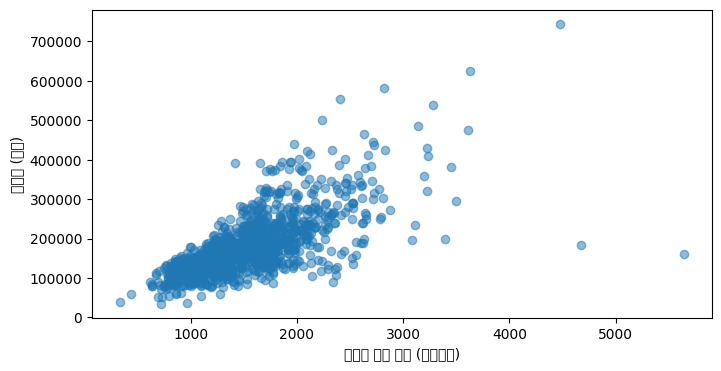

In [12]:
# [제공] 거주 면적과 거래가 (학습용 데이터)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train_df["GrLivArea"], train_df["SalePrice"], alpha=0.5)
ax.set_xlabel("지상층 거주 면적 (평방피트)")
ax.set_ylabel("거래가 (달러)")
plt.show()

OverallQual: 고급 자재와 마감을 쓴 집일수록 건축비와 가치가 높아 가격이 오른다.

면적이 4000평만 피트가 넘는데 거래가 20만달러 안팎인 집이 눈데 뛴다. 비슷한 면적의 다른 집보다 훨씬 싸며, 확인해보니 공사 중 판매된 특수한 거래가 있다.

> **[판단]** 거래가와 가장 관련이 깊어 보이는 숫자 열 세 개를 적고, 왜 그럴지 한 줄씩 설명하세요.
>
> 나의 답:

> **[판단]** 산점도에서 눈에 띄는 점이 있나요? (예: 면적에 비해 값이 이상한 집) 이런 집을 모델에서 빼도 될까요, 두어야 할까요?
>
> 나의 답:

---
# Part 2. 베이스라인 고르기

강의 2-1에서 회귀의 베이스라인은 "모든 집은 평균 가격"이라고 배웠습니다. 그런데 "평균 가격"만이 유일한 선택일까요?

## 2-1. 평균 예측과 중앙값 예측

**[직접 작성]** 학습용 데이터의 거래가 **평균**과 **중앙값**을 각각 평가용 집 전체의 예측값으로 쓴 두 베이스라인을 `evaluate`로 채점하고, 결과 지표를 `m_mean`, `m_median`에 저장하세요. 이어서 두 결과를 `log_result`로 기록합니다.

<details><summary>힌트</summary>

`mean_pred = np.full(len(test_df), train_df["SalePrice"].mean())`로 같은 값을 반복한 배열을 만듭니다. 중앙값도 같은 방식입니다.

`m_mean = evaluate("평균 예측", mean_pred)`, 그다음 `log_result("평균 예측", [], m_mean)`.
</details>

In [13]:
# 여기에 코드를 작성하세요

mean_pred = np.full(len(test_df), train_df["SalePrice"].mean())

m_mean = evaluate("평균 예측", mean_pred)
log_result("평균 에측", [], m_mean)

median_pred = np.full(len(test_df), train_df["SalePrice"].median())
m_median = evaluate("중앙값 예측", median_pred)
log_result("중앙값 예측", [], m_median)

[평균 예측] MAE 62,576 | RMSE 87,619 | R² -0.001 | MAPE 41.4%
[중앙값 예측] MAE 59,568 | RMSE 88,667 | R² -0.025 | MAPE 36.0%


MAE는 중앙값 예측이낮고, RMSE는 평균 예측이 더 낮다.

MAE는 오차를 그대로 더하므로 큰 오차도 크기에 비례해서만 벌주고, 따라서 대다수의 집에 가까운 중앙값이 유리합니다. 반면 RMSE는 오차를 제곱하므로 큰 오차를 훨씬 아프게 보고, 고가 주택 쪽으로 끌려 올라간 평균이 그 큰 오차를 줄여 유리하다.

평균 예측을 베이스라인으로 쓸거 같다. 회귀 모델은 일반적으로 제곱오차를 최소화하도록 학습하는데, 아무 정보도 쓰지 않을 때 제곱 오차를 가장 작게 만드는 값이 평균이므로, 모델과 같은 기준에서 출발하는 가장 공정한 비교대상이다.

> **[판단]** MAE와 RMSE에서 평균 예측과 중앙값 예측 중 어느 쪽이 더 낮은가요? 두 지표에서 결과가 다르다면, 왜 그럴지 "큰 오차를 얼마나 아프게 보는가"로 설명해 보세요.
>
> 나의 답:

> **[판단]** 회귀 모델의 점수를 비교할 베이스라인으로는 둘 중 어느 것을 쓰겠습니까? 이유도 적으세요.
>
> 나의 답:

---
# Part 3. 현행 방법 만들기: 사람의 시세 규칙

모델이 없던 시절에도 중개사들은 나름의 규칙으로 시세를 매겼습니다. 비슷한 집의 평방피트당 단가에 면적을 곱하거나, 같은 동네의 비슷한 집이 얼마에 팔렸는지 떠올리는 식입니다. 여러분이 중개사라면 **정보 두세 개**로 어떤 규칙을 만들겠습니까?

**시세 규칙**: 어떤 정보를 어떻게 쓸지 **내가 정하고**, 숫자(동네별 단가 등)는 학습용 데이터에서 계산하는 방법입니다. Chapter 1에서 배운 규칙 기반(Rule-Based) 방법의 한 예로, 모델이 이겨야 할 비교 기준이 됩니다.

## 시세 규칙을 만들 때의 약속

- 쓰는 정보는 **두세 개를 넘기지 않습니다.** 머릿속으로 계산할 수 있어야 하기 때문입니다.
- 시세 규칙에 쓰는 숫자(동네별 단가, 구간별 중앙값 등)는 **학습용 데이터에서만** 계산합니다.
- 평가용 데이터를 보고 시세 규칙을 고치지 않습니다.

## 3-1. 나의 시세 규칙 만들기

> **[판단]** 나의 시세 규칙(말로): 집의 ______ 와 ______ 를 보고, ______ 를 기준으로 가격을 정한다.
>
> 이 정보를 고른 근거(1-6의 어떤 결과인가):
>
> 나의 답:

**[직접 작성]** 시세 규칙을 코드로 옮겨 평가용 집의 가격을 계산하고, 예측을 `rule_pred`(평가용 `test_df`와 같은 순서의 `Series`)에 저장하세요. 그다음 `evaluate`로 채점하고, 결과를 `m_rule`에 저장한 뒤 `log_result`로 기록합니다.

<details><summary>힌트</summary>

학습용 데이터에서 평방피트당 단가를 구하는 예시입니다.

```python
unit_price = (train_df["SalePrice"] / train_df["GrLivArea"]).median()
rule_pred = test_df["GrLivArea"] * unit_price
```

동네별로 단가를 다르게 쓰려면 단가를 동네별로 구한 뒤 `map`으로 붙입니다.

```python
unit_by_nb = (train_df["SalePrice"] / train_df["GrLivArea"]).groupby(train_df["Neighborhood"]).median()
rule_pred = test_df["Neighborhood"].map(unit_by_nb) * test_df["GrLivArea"]
```

이 예시는 형식만 보여 주는 것입니다. 여러분의 시세 규칙을 쓰세요. 평가용에만 있는 동네가 있을 수 있으니, 빈 값이 생기면 `fillna(train_df["SalePrice"].median())`처럼 채우세요.
</details>

In [14]:
# 여기에 코드를 작성하세요
# 예측은 rule_pred, 채점 결과는 m_rule라는 이름으로 저장하세요 (Part 4, 5에서 다시 씁니다)

# 1. 학습용 데이터로 품질 등급별 평방피트당 단가(중앙값) 계산
unit_by_qual = (train_df["SalePrice"] / train_df["GrLivArea"]).groupby(train_df["OverallQual"]).median()

# 2. 평가용 집에 품질 등급별 단가를 붙여 면적과 곱하기
rule_pred = test_df["OverallQual"].map(unit_by_qual) * test_df["GrLivArea"]

# 3. 학습용에 없던 등급이라 값이 비면 거래가 중앙값으로 채우기
rule_pred = rule_pred.fillna(train_df["SalePrice"].median())

# 4. 채점과 기록
m_rule = evaluate("품질별 단가 × 면적", rule_pred)
log_result("품질별 단가 × 면적", ["OverallQual", "GrLivArea"], m_rule)

[품질별 단가 × 면적] MAE 32,665 | RMSE 44,289 | R² 0.744 | MAPE 21.0%


나의 시세 규칙: 집의 품질 등급(OverallQual)와 지상층 거주 면적(GrLivArea)를 보고, 품질 등급별 평방피트당 단가(중앙값)를 기준으로 가격을 정한다. 즉, 예측 가격 = 그 품질 등급의 평방피트당 단가 × 거주 면적.

OverallQual이 상관이 가장 높았고 GrLivArea도 상위권이었다. 또 거주 면적과 거래가의 산점도에서 면적이 클수록 가격이 오르는 경향이 뚜렷하게 보였습니다. 같은 면적이라도 품질이 높은 집일수록 단위 면적당 가격이 더 높을 것이라고 판단해, 품질 등급별 단가에 면적을 곱하는 방식으로 정했다.

내 시세 규칙의 MAE는 32,655달러로, 평균 예측보다 약 29,900달러, 중앙값 예측보다 약 26,900달러 낮다. 오차가 베이스라인의 절반 가까이로 줄었다.


> **[판단]** 내 시세 규칙의 MAE는 베이스라인(평균·중앙값 예측)보다 얼마나 낮은가요? 정보 두세 개만으로 오차가 이만큼 줄어든다는 것은 무엇을 뜻할까요?
>
> 나의 답:

---
# Part 4. 모델 만들기와 실험 기록

이제 모델을 만들어 내 시세 규칙과 겨룹니다. 강의 Part 2의 코드를 보지 말고 먼저 직접 써 보세요.

## 4-1. 첫 모델: 다중회귀

**[직접 작성]** 아래 순서로 작성하세요.

1. 피처 `["GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars"]`로 `make_data`를 호출해 `X_train, X_test, y_train, y_test`를 만든다
2. `LinearRegression`을 학습한다
3. 학습용과 평가용을 모두 `evaluate`로 채점한다 (학습용은 `y_true=y_train`을 줍니다)
4. 평가용 결과를 `log_result`로 기록한다

<details><summary>힌트</summary>

강의 2-3의 코드와 같은 순서입니다.

```python
m_train = evaluate("학습용", model.predict(X_train), y_true=y_train)
m_test = evaluate("다중회귀 5개", model.predict(X_test))
log_result("다중회귀 5개", features, m_test, m_train)
```
</details>

In [15]:
# 여기에 코드를 작성하세요

# 1. 피처 지정 후 데이터 만들기
features = ["GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars"]
X_train, X_test, y_train, y_test = make_data(features)

# 2. 선형회귀 학습
model = LinearRegression()
model.fit(X_train, y_train)

# 3. 학습용과 평가용 채점
m_train = evaluate("학습용", model.predict(X_train), y_true=y_train)
m_test = evaluate("다중회귀 5개", model.predict(X_test))

# 4. 평가용 결과 기록
log_result("다중회귀 5개", features, m_test, m_train)

[학습용] MAE 24,399 | RMSE 37,970 | R² 0.758 | MAPE 14.5%
[다중회귀 5개] MAE 25,415 | RMSE 39,763 | R² 0.794 | MAPE 15.3%


평가용 MAE는 학습용 보다 약 1000달러, RMSE는 약 1800달러 높아 차이가 작다. R^2는 오히려 평가용이 높다. 과적합이라면 학습용 점수는 매우 좋은데 평가용 점수가 크게 나빠져야 하지만, 이모델은 처음 보는 집에서도 학습용과 거의 비슷한 수준으로 예측하므로 과적합의 신호로 보기 어렵다.

> **[판단]** 이 모델의 학습용 점수와 평가용 점수는 얼마나 차이 나나요? 그 차이는 과적합의 신호일까요?
>
> 나의 답:

## 4-2. 피처와 모델을 바꿔 보기

피처를 늘리거나 모델의 복잡도를 바꿔 가며 **세 번 이상** 실험하세요. 매번 아래 `run`이 학습용·평가용 점수를 모두 채점해 기록해 줍니다.

**[직접 작성]** `run(이름, 피처 목록, 모델)`을 세 번 이상 호출하세요. 다음 세 가지를 모두 포함하면 좋습니다.

- 숫자 피처만 늘려 보기
- 범주형 피처(동네, 마감 품질 등)를 더해 보기
- 모델의 복잡도를 올려 보기 (다항 피처)와, 그에 벌점을 주는 Ridge

<details><summary>힌트</summary>

```python
run("숫자 12개", num_features, LinearRegression())
run("숫자+범주", num_features + cat_features, LinearRegression())
run("3차 다항", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()))
run("3차 다항 + Ridge", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(alpha=100)))
```

`alpha`(벌점의 세기)를 10, 100, 1000으로 바꿔 보면 학습용·평가용 점수가 어떻게 달라지는지 볼 수 있습니다.
</details>

In [16]:
# 1. 숫자 피처만 늘려 보기
run("숫자 12개", num_features, LinearRegression())
print("--------------------------------------------------")

# 2. 범주형 피처 더해 보기
run("숫자+범주", num_features + cat_features, LinearRegression())
print("--------------------------------------------------")

# 3. 모델 복잡도 올리기 (3차 다항)
run("3차 다항", num_features,
    make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()))
print("--------------------------------------------------")

# 4. 3차 다항 + Ridge, alpha를 바꿔 가며 비교
for alpha in [10, 100, 1000]:
    run(f"3차 다항 + Ridge(alpha={alpha})", num_features,
        make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(alpha=alpha)))

[숫자 12개 (학습용)] MAE 22,972 | RMSE 36,605 | R² 0.775 | MAPE 13.7%
[숫자 12개] MAE 24,353 | RMSE 39,231 | R² 0.799 | MAPE 14.5%
--------------------------------------------------
[숫자+범주 (학습용)] MAE 18,428 | RMSE 29,716 | R² 0.852 | MAPE 10.6%
[숫자+범주] MAE 20,172 | RMSE 32,698 | R² 0.861 | MAPE 11.9%
--------------------------------------------------
[3차 다항 (학습용)] MAE 11,736 | RMSE 16,646 | R² 0.954 | MAPE 7.2%
[3차 다항] MAE 29,235 | RMSE 67,319 | R² 0.409 | MAPE 17.8%
--------------------------------------------------
[3차 다항 + Ridge(alpha=10) (학습용)] MAE 12,571 | RMSE 18,059 | R² 0.945 | MAPE 7.7%
[3차 다항 + Ridge(alpha=10)] MAE 22,671 | RMSE 41,122 | R² 0.780 | MAPE 13.5%
[3차 다항 + Ridge(alpha=100) (학습용)] MAE 13,872 | RMSE 19,911 | R² 0.934 | MAPE 8.5%
[3차 다항 + Ridge(alpha=100)] MAE 20,222 | RMSE 32,073 | R² 0.866 | MAPE 12.3%
[3차 다항 + Ridge(alpha=1000) (학습용)] MAE 17,013 | RMSE 23,963 | R² 0.904 | MAPE 10.5%
[3차 다항 + Ridge(alpha=1000)] MAE 20,858 | RMSE 31,688 | R² 0.869 | MAPE 13.2%


**[제공]** 실험 기록표를 평가 MAE 순으로 봅니다.

In [17]:
# [제공] 실험 기록표
pd.DataFrame(experiment_log).sort_values("평가 MAE")

                           실험 피처 수  학습 MAE  학습 RMSE  평가 MAE  평가 RMSE  평가 R²
5                     숫자+범주      18   18428.0    29716.0     20172      32698    0.861
8   3차 다항 + Ridge(alpha=100)      12   13872.0    19911.0     20222      32073    0.866
9  3차 다항 + Ridge(alpha=1000)      12   17013.0    23963.0     20858      31688    0.869
7    3차 다항 + Ridge(alpha=10)      12   12571.0    18059.0     22671      41122    0.780
4                     숫자 12개      12   22972.0    36605.0     24353      39231    0.799
3                  다중회귀 5개       5   24399.0    37970.0     25415      39763    0.794
6                      3차 다항      12   11736.0    16646.0     29235      67319    0.409
2            품질별 단가 × 면적       2       NaN        NaN     32665      44289    0.744
1                   중앙값 예측       -       NaN        NaN     59568      88667   -0.025
0                     평균 에측       -       NaN        NaN     62576      87619   -0.001


범주형 피처를 더하자 평가용 MAE는 24,353dptj 20,172로 약 4200달러, RMSE는 39,231dptj 32698로 약 6500달러 줄었고, R^2는 0.799에서 0.861로 올랐다. 학습용MAE와 평가용 MAE의 차이도 작아, 과적합 없이 새집에서도 서능이 실제로 개선되었다.

이 피처들이 도움이 된 이유는 숫자 피처가 담지 못한 정보를 담고 있기 때문이다. 숫자 피처는 면적, 연식, 품질 점수처럼, “집자체의 크기와 상태”를  나타내지만, 같은 크기와 상태의 집이라도 어느 동네에 있느냐에 따라 가격이 크게 달라진다


차이가 가장 큰 실험은 “3차 다항”이다. 학습용 MAE는 11,736으로 모든 실험 중 가장 낮지만, 평가용 MAE는 29,235로 약 2.5배, RMSE는 16,646에서 67,319로 약 4배 커졌고 평가 R^2도 0.409로 크게 떨어졌다.

이는 과적합이다. 숫자 피처 12개를 3차 다항으로 만들면 피처끼리 곱한 조합이 수백 개로 늘어나 모델이 매우 복잡해진다. 이렇게 자유도가 높은 모델은 학습용 데이터의 일반적인 경향뿐 아니라 우연한 잡음까지  그대로 맞추게 되어, 학습용 점수는 매우 좋지만 처음 보는 평가용 집에서는 크게 틀린다.

가장 좋은 모델의 평가용 MAE는 20,172달러로, 내 시세 규치보다 약 12,500달러, 비율로는 약 38%낮다. 집 한 채당 평균 오차가 12,000달러 이상 줄어드는 것이며, R^2도 0.744에서 0.861로 알라 가격 차이를 더 많이 설명한다.

> **[판단]** 범주형 피처(동네, 마감 품질 등)를 더했을 때 오차가 얼마나 줄었나요? 이 피처들이 왜 도움이 되었을까요?
>
> 나의 답:

> **[판단]** 학습용 점수와 평가용 점수의 차이가 가장 큰 실험은 무엇인가요? Ridge를 쓰면 그 차이가 어떻게 달라졌나요? 강의 Part 3의 "과적합"과 "정규화"로 설명해 보세요.
>
> 나의 답:

> **[판단]** 가장 좋은 모델은 내 시세 규칙보다 MAE가 얼마나(달러, %) 낮은가요? 이 차이라면 기획팀이 모델을 도입할 만할까요?
>
> 나의 답:

## 4-3. Lasso: 피처를 고르는 정규화

4-2의 Ridge는 계수를 **고르게 줄이는** 정규화였습니다. **Lasso**는 벌점의 모양이 달라서, 덜 중요한 계수를 **정확히 0**으로 만듭니다. 계수가 0인 피처는 모델에서 빠진 것과 같으므로, Lasso는 정규화이면서 동시에 피처를 고르는 방법입니다.

| | Ridge | Lasso |
| --- | --- | --- |
| 벌점 | 계수의 제곱합 | 계수의 절댓값합 |
| 계수가 줄어드는 방식 | 모두 고르게, 0이 되지는 않음 | 덜 중요한 것부터 정확히 0 |

이 절에서는 Lasso가 실제로 어떤 피처를 버리는지 세 가지 실험으로 확인합니다. 세 실험 모두 실험 기록표(`experiment_log`)에는 남기지 않습니다.

### 실험 1. 계수 비교: 무엇이 0이 되는가

**[직접 작성]** 숫자 피처 12개(`num_features`)로 세 모델을 학습하고, 계수를 한 표로 비교하세요. 세 모델 모두 `StandardScaler`를 앞에 붙입니다(표준화해야 계수끼리 비교할 수 있습니다).

- 선형회귀 (`LinearRegression()`)
- Ridge (`Ridge(alpha=100)`)
- Lasso (`Lasso(alpha=5000)`)

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features)
coefs = {}
for name, reg in [("선형회귀", LinearRegression()), ("Ridge 100", Ridge(alpha=100)), ("Lasso 5000", Lasso(alpha=5000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coefs[name] = m[-1].coef_          # 파이프라인의 마지막 단계(모델)의 계수
pd.DataFrame(coefs, index=X_tr.columns).round(0)
```

`m[-1]`은 파이프라인의 마지막 단계, 즉 모델입니다.
</details>

In [18]:
# 여기에 코드를 작성하세요

# 숫자 피처 12개로 데이터 만들기
X_train, X_test, y_train, y_test = make_data(num_features)

# 세 모델 정의 (모두 StandardScaler 앞에 붙이기)
models = {
    "선형회귀": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge(100)": make_pipeline(StandardScaler(), Ridge(alpha=100)),
    "Lasso(5000)": make_pipeline(StandardScaler(), Lasso(alpha=5000)),
}

# 학습 후 계수 모으기
coefs = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    coefs[name] = model[-1].coef_   # 파이프라인의 마지막 단계(회귀 모델)의 계수

coef_df = pd.DataFrame(coefs, index=X_train.columns).round(0)
coef_df.sort_values("선형회귀", ascending=False)
coef_df[coef_df["Lasso(5000)"] == 0]

              선형회귀  Ridge(100)  Lasso(5000)
FullBath       -3116.0      -790.0          0.0
TotRmsAbvGrd    1805.0      4033.0          0.0


Lasso가 0으로 만든 피처는 TotRmsAbvGrd와 FullBath이다, 하지만 이 피처들이 집값과 관계가 없는 것은 아니다. 1-6의 상관표에서 두 피처 모두 거래가와 양의 상관을 보였다 방과 욕실이 많은 집이 더 비싸다는것은 상식적으로 자연스럽다

> **[판단]** Lasso가 0으로 만든 피처는 무엇인가요? 그 피처들은 집값과 정말 관계가 없을까요? 1-6의 상관표나 다른 피처와의 관계를 떠올려 설명해 보세요.
>
> 나의 답:

### 실험 2. 잡음 피처를 섞으면

**[제공]** 아무 의미 없는 무작위 숫자 열 5개(`noise0`~`noise4`)를 데이터에 추가합니다. 집값과 전혀 관계가 없는 열입니다.

In [19]:
# [제공] 무작위 잡음 피처 5개 추가 (씨앗 고정)
rng = np.random.RandomState(0)
noise_features = [f"noise{i}" for i in range(5)]
for col in noise_features:
    df[col] = rng.randn(len(df))
print(df[noise_features].describe().round(2).loc[["mean", "std"]])

      noise0  noise1  noise2  noise3  noise4
mean   -0.02   -0.03   -0.02    0.02   -0.02
std     0.98    0.96    1.01    0.99    0.99


**[직접 작성]** `num_features + noise_features`로 선형회귀와 Lasso(`alpha=1000`)를 학습하세요. 각 모델에서

1. 잡음 피처 5개의 계수
2. 계수가 정확히 0이 된 피처 목록
3. 평가용 점수 (`evaluate`로 채점)

를 출력합니다.

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features + noise_features)
m = make_pipeline(StandardScaler(), Lasso(alpha=1000)).fit(X_tr, y_tr)
coef = pd.Series(m[-1].coef_, index=X_tr.columns)
print(coef[noise_features].round(0))
print("0이 된 피처:", list(coef[coef == 0].index))
evaluate("Lasso + 잡음", m.predict(X_te))
```
</details>

In [20]:
# 여기에 코드를 작성하세요

# 숫자 피처 + 잡음 피처로 데이터 만들기
X_tr, X_te, y_tr, y_te = make_data(num_features + noise_features)

# ===== 1) 선형회귀 =====
lr = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
coef_lr = pd.Series(lr[-1].coef_, index=X_tr.columns)

print("[선형회귀] 잡음 피처 계수")
print(coef_lr[noise_features].round(0))
print("[선형회귀] 0이 된 피처:", list(coef_lr[coef_lr == 0].index))
m_lr_noise = evaluate("선형회귀 + 잡음", lr.predict(X_te))

# ===== 2) Lasso =====
lasso = make_pipeline(StandardScaler(), Lasso(alpha=1000)).fit(X_tr, y_tr)
coef_lasso = pd.Series(lasso[-1].coef_, index=X_tr.columns)

print("[Lasso] 잡음 피처 계수")
print(coef_lasso[noise_features].round(0))
print("[Lasso] 0이 된 피처:", list(coef_lasso[coef_lasso == 0].index))
m_lasso_noise = evaluate("Lasso + 잡음", lasso.predict(X_te))

[선형회귀] 잡음 피처 계수
noise0   -696.0
noise1    497.0
noise2   -144.0
noise3   -732.0
noise4   -175.0
dtype: float64
[선형회귀] 0이 된 피처: []
[선형회귀 + 잡음] MAE 24,300 | RMSE 39,230 | R² 0.799 | MAPE 14.5%
[Lasso] 잡음 피처 계수
noise0   -0.0
noise1    0.0
noise2    0.0
noise3   -0.0
noise4   -0.0
dtype: float64
[Lasso] 0이 된 피처: ['FullBath', 'noise0', 'noise1', 'noise2', 'noise3', 'noise4']
[Lasso + 잡음] MAE 24,184 | RMSE 39,522 | R² 0.796 | MAPE 14.3%


선형회귀는 집값과 아무 관계없는 잡음 피처 5개에 -732에서497까지 모두 0이 아닌 계수를주었다 계수가 0이 된 피처는 하나도 없다. 학습데이터에 우연히 생긴 작은 패턴까지 맞추려 했기 때문이다.

라쏘는 잡음 피처 5개의 계수를 모두 정확히 0으로 만들어 모델에서 제외했다. 평가용 점수는 선형회귀와 거의 같다.  

MAE는 24,300에서 24,184로 약 120달러 낮아졌고, RMSE는 39,230에서 39,522로 약 290달러 높아졌다. R^2는 0.799와 0.796으로 비슷했다, 즉 라쏘는 점수를 크게바꾸지 않으면서 쓸모없는 피처를 걸러내, 같은 성능을 더 단순하고 해석하기쉬운 모델로 만들었다

> **[판단]** 선형회귀는 잡음 피처에 어떤 계수를 주었나요? 이 계수표만 보고 보고서를 쓰면 어떤 오해가 생길까요? Lasso는 잡음을 어떻게 다뤘고, 평가용 점수는 어떻게 달라졌나요?
>
> 나의 답:

### 실험 3. 범주형까지 넣은 모델에 Lasso를 걸면

**[직접 작성]** 4-2에서 가장 좋았던 피처 조합(`num_features + cat_features`, 원핫 인코딩 후 열 67개)에 Lasso를 걸고, `alpha`를 100, 300, 1000, 3000으로 바꿔 가며 다음을 표로 정리하세요.

- 0이 아닌 계수의 수
- 평가용 MAE와 RMSE

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features + cat_features)
rows = []
for a in [100, 300, 1000, 3000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    rows.append({"alpha": a, "남은 피처 수": int((m[-1].coef_ != 0).sum()),
                 "평가 MAE": round(mean_absolute_error(y_te, p)),
                 "평가 RMSE": round(np.sqrt(mean_squared_error(y_te, p)))})
pd.DataFrame(rows)
```

비교 기준은 실험 기록표의 "숫자+범주"(선형회귀) 줄입니다.
</details>

In [21]:
# 여기에 코드를 작성하세요

# 숫자 + 범주 피처 (원핫 인코딩 후 열 67개)
X_tr, X_te, y_tr, y_te = make_data(num_features + cat_features)
print("전체 피처 수:", X_tr.shape[1])

rows = []
for a in [100, 300, 1000, 3000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    rows.append({
        "alpha": a,
        "남은 피처 수": int((m[-1].coef_ != 0).sum()),
        "평가 MAE": round(mean_absolute_error(y_te, p)),
        "평가 RMSE": round(np.sqrt(mean_squared_error(y_te, p))),
    })

lasso_table = pd.DataFrame(rows)
lasso_table

전체 피처 수: 67
   alpha  남은 피처 수  평가 MAE  평가 RMSE
0    100            57     20090      32704
1    300            49     20030      32767
2   1000            34     19946      33056
3   3000            25     20717      34903


크게 나아지지 않았다. MAE는 alpha 1000까지 조금씩 줄어 19,946으로 선형회귀보다 약 230달러 낮아졌지만, alpha 3000에서는 오히려 20,717로 나빠졌다.

성능이 거의 같다면 더 단순한 모델을 쓰는 것이 일발적으로 낮다. 실제로 라쏘는67개 피처중 34개만 남기고도 평가 MAE가 19,946으로 선형회귀와 거의 같거나 오히려 조금 낮았다. 단순한 모델은 예측 근거를 설명하기 쉽고, 관리할 항목이 적어 운여 부담이 줄며, 쓸모없는 정보에 휘둘릴 위험도 적다.

> **[판단]** Lasso는 "숫자+범주" 선형회귀보다 나아졌나요? MAE와 RMSE가 같은 방향으로 움직였나요? 4-2의 3차 다항 실험에서 Ridge가 큰 효과를 냈던 것과 비교해, 여기서 효과가 작은 이유를 "이 모델이 과적합했는가"로 설명해 보세요.
>
> 나의 답:

> **[판단]** 기획팀이 "피처를 절반만 써도 비슷하다면 더 단순한 모델이 낫지 않나요?"라고 묻습니다. 어떻게 답하겠습니까?
>
> 나의 답:

---
# Part 5. 오차 들여다보기와 보고

지표 하나로는 "믿어도 되는 집"과 "믿으면 안 되는 집"을 구분할 수 없습니다. 오차가 어디에 몰려 있는지 직접 봅니다.

## 5-1. 가격대별 오차

**[직접 작성]** 기록표에서 평가 MAE가 가장 낮은 실험을 골라 그 이름을 `best_name`에 저장하고, 그 실험의 예측을 `best_pred`에 저장하세요. 그다음 `error_by_price`로 **내 시세 규칙**과 **최고 모델**의 가격대별 오차를 각각 출력합니다.

<details><summary>힌트</summary>

모든 실험의 예측은 `preds`에 이름으로 저장되어 있습니다. `best_name = "숫자+범주"`처럼 이름을 직접 적고 `best_pred = preds[best_name]`로 꺼내세요.

`error_by_price(preds["내 시세 규칙"])`, `error_by_price(best_pred)`
</details>

In [22]:
# 여기에 코드를 작성하세요

best_name = "숫자+범주"
best_pred = preds[best_name]

print("===== 내 시세 규칙 =====")
error_by_price(preds["품질별 단가 × 면적"])

print("===== 최고 모델:", best_name, "=====")
error_by_price(best_pred)

===== 내 시세 규칙 =====
===== 최고 모델: 숫자+범주 =====
                  집 수       MAE  평균 편향(실제−예측)
SalePrice                                              
(0, 100000]          26   20945.0              -14409.0
(100000, 200000]    184   13752.0               -2168.0
(200000, 300000]     58   24376.0                3782.0
(300000, 500000]     21   38577.0               25190.0
(500000, 800000]      3  197086.0              197086.0


최고 모델은 50만~80만 달러 구간에서 오차가 가장 크다. MAE가 197,986달러로 다른 구간보다 훨씬 크코, 평균편향도 197,086으로 양수다. 편향과 MAE가 같다는 것은 이 구간 3채 모두 실제보다 싸게 예측했다는 뜻이다. 

> **[판단]** 어느 가격대에서 오차(MAE)가 가장 큰가요? 그 가격대의 "평균 편향"은 양수(실제가 더 비쌈)인가요, 음수인가요? 모델과 시세 규칙이 같은 방향으로 틀리나요?
>
> 나의 답:

## 5-2. 잔차 그림

**[직접 작성]** 최고 모델의 잔차(실제 − 예측)를 예측 가격에 대해 산점도로 그리세요. 0을 나타내는 가로선도 함께 그립니다.

<details><summary>힌트</summary>

강의 2-7의 코드와 같습니다.

```python
residual = y_test - best_pred
plt.scatter(best_pred, residual, alpha=0.5)
plt.axhline(0, color="gray")
```
</details>

<lms-runtime>:1399: UserWarning: Glyph 51092 (\N{HANGUL SYLLABLE JAN}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 45804 (\N{HANGUL SYLLABLE DAL}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 47084 (\N{HANGUL SYLLABLE REO}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 49707 (\N{HANGUL SYLLABLE SUS}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 51088 (\N{HANGUL S

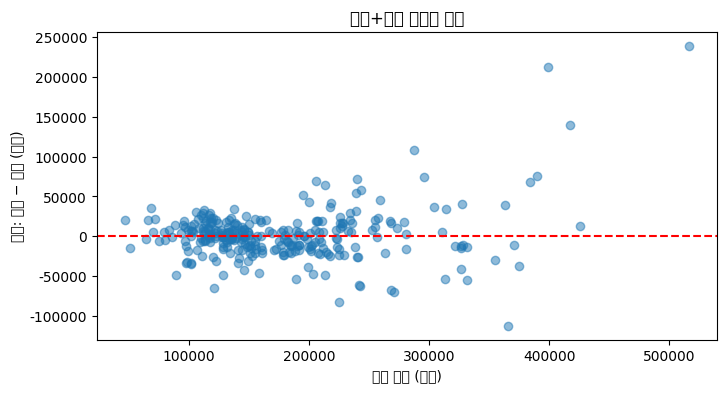

In [23]:
# 여기에 코드를 작성하세요

y_true = test_df["SalePrice"].values
y_pred = np.asarray(best_pred)
residual = y_true - y_pred   # 잔차 = 실제 − 예측

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(y_pred, residual, alpha=0.5)
ax.axhline(0, color="red", linestyle="--")   # 0 기준선
ax.set_xlabel("예측 가격 (달러)")
ax.set_ylabel("잔차: 실제 − 예측 (달러)")
ax.set_title(f"{best_name} 모델의 잔차")
plt.show()

최고 모델은 50만~80만 달러 구간에서 오차가 가장 크다. MAE가 197,986달러로 다른 구간보다 훨씬 크코, 평균편향도 197,086으로 양수다. 편향과 MAE가 같다는 것은 이 구간 3채 모두 실제보다 싸게 예측했다는 뜻이다. 
잔차 그림에서 예측 가격이 커질수록 점들이 위아래로 더 넓게 퍼지는 깔때기 모양이다. 예측 가격 20만 달러 이하에서는 잔차가 대부분 +-5만원 달러 안에 모여 있지만, 20만~30만 달러에 서는 +-7만~8만 달러까지 퍼지고, 30만 달러 이상에서는 +-10만 달러를 넘는 점들이 나타난다. 즉 집이 비쌀수록 오차의 크기가 커진다

> **[판단]** 잔차 그림에서 규칙이 보이나요? 예측 가격이 높은 쪽에서 점들이 어떻게 흩어져 있나요?
>
> 나의 답:

## 5-3. 가장 크게 틀린 집 들여다보기

**[직접 작성]** 최고 모델이 가장 크게 틀린 집 10채를 골라 실제 거래가, 예측 가격, 면적(`GrLivArea`), 품질(`OverallQual`), 동네(`Neighborhood`)를 한 표로 출력하세요.

<details><summary>힌트</summary>

`test_df.assign(예측=best_pred, 오차=y_test - best_pred)`로 열을 붙인 뒤, 오차의 절댓값으로 정렬합니다. `sort_values("오차", key=abs, ascending=False).head(10)`.
</details>

In [24]:
# 여기에 코드를 작성하세요

worst10 = (
    test_df.assign(예측=np.asarray(best_pred).round(0),
                   오차=test_df["SalePrice"].values - np.asarray(best_pred).round(0))
           .sort_values("오차", key=abs, ascending=False)
           .head(10)
)

worst10[["SalePrice", "예측", "오차", "GrLivArea", "OverallQual", "Neighborhood"]]

      SalePrice      예측      오차  GrLivArea  OverallQual Neighborhood
691      755000  516019.0  238981.0       4316           10      NoRidge
898      611657  398955.0  212702.0       2364            9      NridgHt
1046     556581  417006.0  139575.0       2868            9      StoneBr
581      253293  365415.0 -112122.0       2042            8      NridgHt
774      395000  286980.0  108020.0       1973            8      NridgHt
588      143000  225154.0  -82154.0       1473            5      ClearCr
1243     465000  389555.0   75445.0       2076           10      NridgHt
585      369900  295269.0   74631.0       2028            8       Timber
218      311500  240172.0   71328.0       1954            7      Crawfor
1173     200500  270721.0  -70221.0       3086            5      ClearCr


크게 틀린 집 10채 중 7채가 잔차가 양수, 즉 실제보다 싸게 예측된 집입니다. 특히 가장 크게 틀린 상위 3채는 실제 거래가가 55만 달러 이상, 품질 등급이 9~10으로 최상위이며, NoRidge, NridgHt, StoneBr 같은 고가 동네에 있다. 10채 중 7채가 품질 8 이상이고, NridgHt만 4채가 등장한다. 즉 고품질·고가 동네의 비싼 집을 실제보다 낮게 평가하는 경향이 가장 두드러진다.

1.품질 등급(OverallQual)이 9 이상인 집

2.모델의 예측 가격이 35만 달러 이상인 집

3.면적이 매우 크지만 품질 등급이 낮은(예: 5 이하) 집처럼 일반적이지 않은 조합

> **[판단]** 크게 틀린 집들에게 공통점이 있나요? 기획팀이 "이런 매물에는 자동 시세를 쓰지 말자"고 한다면 어떤 기준(가격대, 품질 등)을 제안하겠습니까?
>
> 나의 답:

## 5-4. 가격 맞히기

곧 다른 수강생들의 결과와 함께 비교합니다. 그 전에 **사람의 감**으로 세 채의 가격을 먼저 맞혀 봅니다.

**[제공]** 평가용 집 세 채의 정보를 보여 줍니다. (거래가는 보여 주지 않습니다.)

In [25]:
# [제공] 맞혀 볼 집 세 채 (거래가는 숨김)
_s = test_df.sort_values("SalePrice")
guess_ids = [_s.index[int(q * (len(_s) - 1))] for q in (0.05, 0.5, 0.99)]
show_cols = ["Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars", "KitchenQual"]
test_df.loc[guess_ids, show_cols]

     Neighborhood  GrLivArea  OverallQual  YearBuilt  TotalBsmtSF  GarageCars KitchenQual
649       MeadowV        630            4       1970          630           0          TA
1299        NAmes       1246            5       1959         1246           1          Gd
1243      NridgHt       2076           10       2006         2076           3          Ex


**[직접 작성]** 위 표만 보고, 세 집의 거래가를 직관으로 적으세요. (`my_guess`의 0을 달러 숫자로 바꿉니다.)

In [26]:
# 위 표의 순서대로 세 집의 거래가(달러)를 적으세요
my_guess = {guess_ids[0]: 85000, guess_ids[1]: 140000, guess_ids[2]: 380000}


**[제공]** 실제 거래가를 공개합니다. 내 감, 내 시세 규칙, 최고 모델의 예측을 나란히 봅니다.

In [27]:
# [제공] 정답 공개
reveal = pd.DataFrame({
    "실제 거래가": y_test.loc[guess_ids],
    "내 감": pd.Series(my_guess),
    "내 시세 규칙": preds["품질별 단가 × 면적"].loc[guess_ids],
    "최고 모델": best_pred.loc[guess_ids],
})
for col in ["내 감", "내 시세 규칙", "최고 모델"]:
    reveal[col + " 오차"] = (reveal[col] - reveal["실제 거래가"]).abs()
reveal.round(0)

      실제 거래가   내 감  내 시세 규칙  최고 모델  내 감 오차  내 시세 규칙 오차  최고 모델 오차
649         84500   85000       62612.0    79394.0         500            21888.0          5106.0
1299       154000  140000      145079.0   140022.0       14000             8921.0         13978.0
1243       465000  380000      345536.0   389555.0       85000           119464.0         75445.0


> **[판단]** 세 방법(내 감, 내 시세 규칙, 모델) 중 가장 가까웠던 것은 무엇인가요? 가장 비싼 집에서는 어땠나요? 5-1의 결과와 연결해서 설명해 보세요.
>
> 나의 답:

## 5-5. 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 틀려도 괜찮습니다. 예상이 빗나간 지점이 가장 많이 배우는 곳입니다.

시세 규칙은 나의 시세 규칙 하나만 있는 것이 아닙니다. 다른 정보를 골랐다면 결과도 달랐을 것입니다. 다음 절에서는 아래 **후보 정보 5개** 중 1개 또는 2개를 고르고, **계산법 2가지** 중 하나를 쓰는 시세 규칙을 **모두** 만들어 채점합니다. 정보 조합 5 + 10 = 15가지 × 계산법 2가지 = **30개**입니다.

| 후보 정보 | 나누는 방법 |
| --- | --- |
| 동네 (`Neighborhood`) | 동네 이름 그대로 |
| 품질 등급 (`OverallQual`) | 1~10 등급 그대로 |
| 거주 면적 (`GrLivArea`) | 학습용 기준 5구간 (집 수가 같도록) |
| 건축 연도 (`YearBuilt`) | 학습용 기준 5구간 (집 수가 같도록) |
| 차고 차량 수 (`GarageCars`) | 0~4대 그대로 |

| 계산법 | 뜻 |
| --- | --- |
| (가) 그룹 중앙값 | 같은 그룹 집들의 거래가 중앙값을 그대로 시세로 쓴다 |
| (나) 그룹 단가 × 면적 | 같은 그룹 집들의 평방피트당 단가 중앙값에 그 집의 거주 면적을 곱한다 |

예: "동네 + 품질 등급, (가)"는 "같은 동네·같은 품질 등급 집들의 거래가 중앙값"을 시세로 쓰는 규칙입니다. 모든 그룹의 숫자는 학습용 데이터에서만 계산합니다.

> **[판단]** 예상 ① 기록표에서 가장 좋은 모델(평가 MAE 약 20,000달러)은 시세 규칙 30개 중 몇 개보다 MAE가 낮을까요?
>
> 나의 답:

> **[판단]** 예상 ② 30개 중 MAE가 가장 낮은 시세 규칙은 어떤 정보를 쓰고, 어떤 계산법일까요? 이유도 적어 보세요.
>
> 나의 답:

## 5-6. 시세 규칙 30개 채점하기

**[직접 작성]** `my_rule_text`에 나의 시세 규칙을 한 줄로 적으세요. 아래 결과에서 나의 시세 규칙을 표시할 때 씁니다. (예: `"동네별 평방피트당 단가 × 거주 면적"`)

In [28]:
my_rule_text = "품질별 단가 × 면적"

**[제공]** 후보 정보 5개 중 1~2개 × 계산법 2가지로 시세 규칙 30개를 만들고, 평가용 데이터에서 채점합니다.

In [29]:
# [제공] 시세 규칙 30개 만들기
from itertools import combinations

def train_bins(col, q=5):
    """학습용 데이터로 집 수가 같은 q개 구간의 경계를 정하고, 그 경계로 학습용·평가용을 나눕니다."""
    edges = np.unique(np.quantile(train_df[col], np.linspace(0, 1, q + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    return pd.cut(train_df[col], edges).astype(str), pd.cut(test_df[col], edges).astype(str)

groupers = {
    "동네": (train_df["Neighborhood"].astype(str), test_df["Neighborhood"].astype(str)),
    "품질 등급": (train_df["OverallQual"].astype(str), test_df["OverallQual"].astype(str)),
    "면적 구간": train_bins("GrLivArea"),
    "연도 구간": train_bins("YearBuilt"),
    "차고": (train_df["GarageCars"].astype(str), test_df["GarageCars"].astype(str)),
}
price_tr = train_df["SalePrice"]
unit_tr = train_df["SalePrice"] / train_df["GrLivArea"]

rows = []
for n in [1, 2]:
    for combo in combinations(groupers, n):
        key_tr = groupers[combo[0]][0].copy()
        key_te = groupers[combo[0]][1].copy()
        for c in combo[1:]:
            key_tr = key_tr + " | " + groupers[c][0]
            key_te = key_te + " | " + groupers[c][1]
        # (가) 그룹 중앙값
        med = price_tr.groupby(key_tr).median()
        pred_a = key_te.map(med).fillna(price_tr.median())
        # (나) 그룹 단가 × 면적
        unit = unit_tr.groupby(key_tr).median()
        pred_b = key_te.map(unit).fillna(unit_tr.median()) * test_df["GrLivArea"]
        for method, pred in [("(가) 그룹 중앙값", pred_a), ("(나) 그룹 단가 × 면적", pred_b)]:
            err = (test_df["SalePrice"] - pred).abs()
            rows.append({"정보": " + ".join(combo), "정보 수": n, "계산법": method, "평가 MAE": float(err.mean())})

rules = pd.DataFrame(rows).sort_values("평가 MAE", ignore_index=True)
print("만든 시세 규칙 수:", len(rules))
rules.head(10).round(0)

만든 시세 규칙 수: 30
                    정보  정보 수                 계산법  평가 MAE
0  품질 등급 + 면적 구간        2  (나) 그룹 단가 × 면적   25031.0
1  품질 등급 + 면적 구간        2       (가) 그룹 중앙값   26569.0
2       동네 + 면적 구간        2  (나) 그룹 단가 × 면적   26712.0
3       동네 + 면적 구간        2       (가) 그룹 중앙값   26821.0
4       동네 + 품질 등급        2       (가) 그룹 중앙값   27599.0
5       품질 등급 + 차고        2       (가) 그룹 중앙값   28281.0
6  품질 등급 + 연도 구간        2       (가) 그룹 중앙값   29385.0
7       면적 구간 + 차고        2  (나) 그룹 단가 × 면적   29402.0
8       동네 + 품질 등급        2  (나) 그룹 단가 × 면적   29580.0
9  면적 구간 + 연도 구간        2  (나) 그룹 단가 × 면적   29676.0


**[제공]** 가장 좋은 모델과 나의 시세 규칙이 30개 규칙 사이에서 어디쯤인지 봅니다.

가장 좋은 모델 [숫자+범주] 평가 MAE 20,172
  MAE로 이기는 시세 규칙: 30개 / 30개
나의 시세 규칙 [품질별 단가 × 면적] 평가 MAE 32,665
  30개 중 나보다 MAE가 낮은 시세 규칙: 20개

정보 수 × 계산법별 MAE 중앙값
계산법   (가) 그룹 중앙값  (나) 그룹 단가 × 면적
정보 수                                         
1                 39265.0                32983.0
2                 30329.0                29749.0
<lms-runtime>:1399: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 49464 (\N{HANGUL SYLLABLE SE}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 44508 (\N{HANGUL SYLLABLE GYU}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 52825 (\N{HANGUL SYLLABLE CIG}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 45230 (\N{HANGUL SYLLABLE NAJ}) missing from font(s) DejaVu Sans.
<lms-runtime>:1399: UserWarning: Glyph 51008 (\N

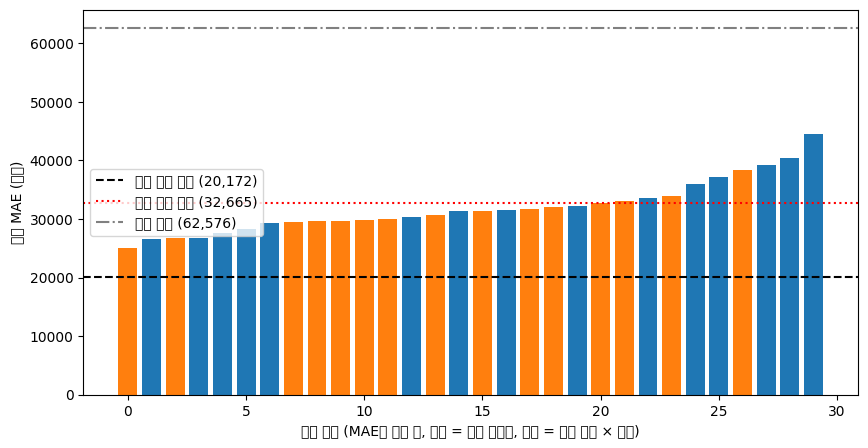

In [30]:
# [제공] 모델과 나의 시세 규칙의 위치
_log = pd.DataFrame(experiment_log)
_models = _log[_log["학습 MAE"].notna()]
_best = _models.sort_values("평가 MAE", kind="stable").iloc[0]
best_mae = float(_best["평가 MAE"])
my_mae = float(m_rule["MAE"])

print(f"가장 좋은 모델 [{_best['실험']}] 평가 MAE {best_mae:,.0f}")
print(f"  MAE로 이기는 시세 규칙: {(rules['평가 MAE'] > best_mae).sum()}개 / {len(rules)}개")
print(f"나의 시세 규칙 [{my_rule_text}] 평가 MAE {my_mae:,.0f}")
print(f"  30개 중 나보다 MAE가 낮은 시세 규칙: {(rules['평가 MAE'] < my_mae).sum()}개")
print()
print("정보 수 × 계산법별 MAE 중앙값")
print(rules.pivot_table(index="정보 수", columns="계산법", values="평가 MAE", aggfunc="median").round(0))

fig, ax = plt.subplots(figsize=(10, 5))
colors = rules["계산법"].map({"(가) 그룹 중앙값": "tab:blue", "(나) 그룹 단가 × 면적": "tab:orange"})
ax.bar(range(len(rules)), rules["평가 MAE"], color=colors)
ax.axhline(best_mae, color="black", linestyle="--", label=f"가장 좋은 모델 ({best_mae:,.0f})")
ax.axhline(my_mae, color="red", linestyle=":", label=f"나의 시세 규칙 ({my_mae:,.0f})")
ax.axhline(m_mean["MAE"], color="gray", linestyle="-.", label=f"평균 예측 ({m_mean['MAE']:,.0f})")
ax.set_xlabel("시세 규칙 (MAE가 낮은 순, 파랑 = 그룹 중앙값, 주황 = 그룹 단가 × 면적)")
ax.set_ylabel("평가 MAE (달러)")
ax.legend(loc="center left")
plt.show()

## 5-7. 결과를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답:

> **[판단]** 정보를 1개 쓴 규칙과 2개 쓴 규칙, 계산법 (가)와 (나) 중 어느 쪽의 MAE가 대체로 낮은가요? 계산법 (나)가 유리하거나 불리한 경우는 어떤 정보를 쓸 때인지도 표에서 찾아 보세요.
>
> 나의 답:

> **[판단]** 가장 좋은 시세 규칙과 가장 좋은 모델의 MAE 차이는 얼마인가요? 이 차이와, 시세 규칙은 누구나 이해하고 바로 쓸 수 있다는 점을 함께 놓고 보면 기획팀에 무엇을 권하겠습니까?
>
> 나의 답:

> **[판단]** 나의 시세 규칙은 30개 사이에서 어디쯤인가요? 정보를 하나 더하거나 계산법을 바꾼다면 어떤 규칙을 고르겠습니까? 위 표에서 그 규칙을 찾아 결과를 적어 보세요.
>
> 나의 답:

## 5-6. 기획팀 보고 메모

분석 결과를 기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **오차를 어떤 지표로 말할 것인가**: MAE와 RMSE 중 하나를 고르고, 의뢰서의 문장("너무 다르면 플랫폼을 믿지 않게 된다")에 근거해 이유를 쓴다. "평균적으로 ±얼마"를 달러로 적는다.
2. **지금 쓰는 방법(내 시세 규칙)과 비교해 얼마나 나은가**
3. **믿어도 되는 집과 믿으면 안 되는 집**: 5-1의 가격대별 오차에 근거해 구분 기준을 제안한다.
4. **주의할 점**: 1-4의 빈 값 처리 결정, 데이터의 한계(Ames 한 도시의 2006~2010년 거래), 아직 확인하지 못한 것

> **[판단]** 기획팀 보고 메모:
>
> 1. 오차 지표와 ±얼마:
>
> 2. 시세 규칙과의 비교:
>
> 3. 믿어도 되는 집 / 믿으면 안 되는 집:
>
> 4. 주의할 점:
>
> 나의 답:

---
# 마무리

## 이 Chapter의 판단 포인트

> **MAE와 RMSE 중 무엇을 보고서에 쓸 것인가? 큰 오차를 얼마나 아프게 볼지는 지표가 아니라 비즈니스가 정한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "회귀 모델의 오차를 보면 평균 예측과 현행 시세 규칙의 오차를 먼저 찾는다."

> **[판단]** 나의 체크리스트 2번(회귀 지표를 볼 때):
>
> 나의 답:

> **[판단]** 나의 체크리스트 3번(학습용 점수와 평가용 점수를 볼 때):
>
> 나의 답:

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 3에서는 확률을 예측하는 **분류**를 배웁니다.